#1. Load the data

In [127]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("vgsales.csv")
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [128]:

print(df.shape)

(16598, 11)


In [129]:
# column names, data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  str    
 2   Platform      16598 non-null  str    
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  str    
 5   Publisher     16540 non-null  str    
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 1.4 MB


In [130]:
# missing values in each column?
df.isnull().sum()

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

**What I notice:**
- `Year` has missing values (the file has the text `N/A` there, pandas turns it into NaN)
- `Publisher` also has missing values
- `Year` is a float (like 2006.0) but years should be whole numbers

#2. Clean the data
All the cleaning steps in one cell:
1. Missing publishers become "Unknown"
2. Rows with no year are dropped, and year becomes a whole number
3. Wrong years are removed
4. Duplicates are removed
5. Same publisher with different spellings is fixed
6. The index and Rank are tidied

In [ ]:
rows_before = len(df)

# Step 1 - missing publisher. the file already uses the word "Unknown" in some rows, so use the same word for the missing ones
df["Publisher"] = df["Publisher"].fillna("Unknown")

# Step 2 - missing year . guessing the years of games release is unethical hence we drop the rows
df = df.dropna(subset=["Year"])
df["Year"] = df["Year"].astype(int)    # now no missing years, so float (2006.0) can become int (2006)

# Step 3 - years that don't make sense
# the data was collected around 2016, so later years (2017, 2020) are not finished or wrong
# a DS game from 1985 is also wrong because the Nintendo DS came out in 2004
wrong_future = df["Year"] > 2016
wrong_ds = (df["Platform"] == "DS") & (df["Year"] < 2004)
df = df[~wrong_future & ~wrong_ds]

# Step 4: duplicates
# the same game on the same platform in the same year should only appear once
df = df.drop_duplicates(subset=["Name", "Platform", "Year"])

# Step 5: same publisher, different spelling
df["Publisher"] = df["Publisher"].replace("Big Ben Interactive", "Bigben Interactive")
df["Publisher"] = df["Publisher"].replace("Milestone S.r.l", "Milestone S.r.l.")



# Step 6: tidy the index and Rank
# rows were removed so there are gaps in the numbers, the data is sorted by sales so just number it again
df = df.reset_index(drop=True)
df["Rank"] = range(1, len(df) + 1)

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(df))

Rows before cleaning: 16598
Rows after cleaning: 14852


In [132]:
# save the clean data in a new file so the original stays the same
df.to_csv("vgsales_clean.csv", index=False)

## 3. Charts

### Chart 1: How many games came out each year?

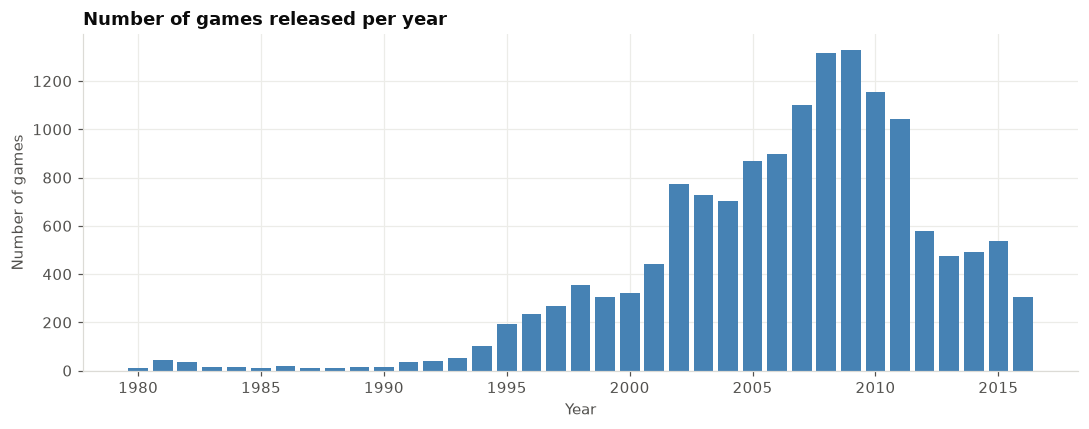

In [133]:
games_per_year = df["Year"].value_counts().sort_index()

plt.figure(figsize=(10, 4))
plt.bar(games_per_year.index, games_per_year.values, color="steelblue")
plt.title("Number of games released per year")
plt.xlabel("Year")
plt.ylabel("Number of games")
plt.tight_layout()
plt.show()

### Chart 2: Total sales per year

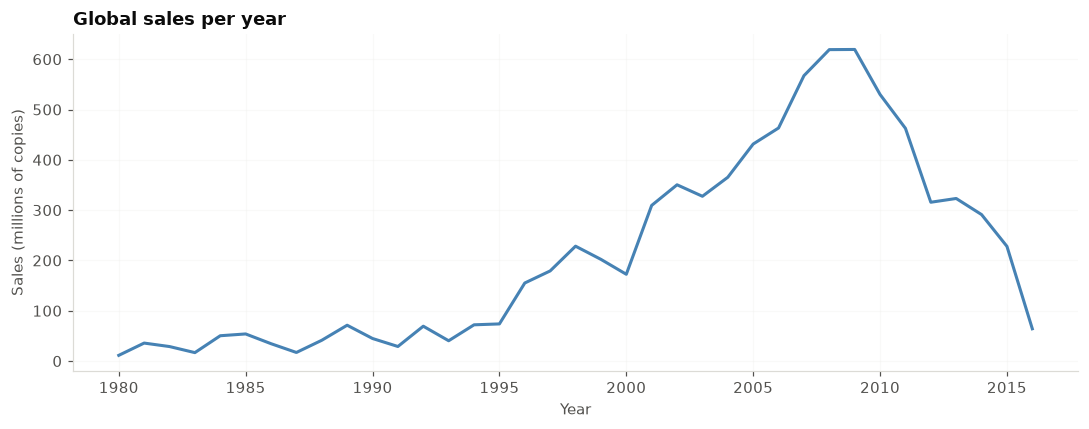

In [134]:
sales_per_year = df.groupby("Year")["Global_Sales"].sum()

plt.figure(figsize=(10, 4))
plt.plot(sales_per_year.index, sales_per_year.values, color="steelblue", linewidth=2)
plt.title("Global sales per year")
plt.xlabel("Year")
plt.ylabel("Sales (millions of copies)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Chart 3: Which genres sell the most?

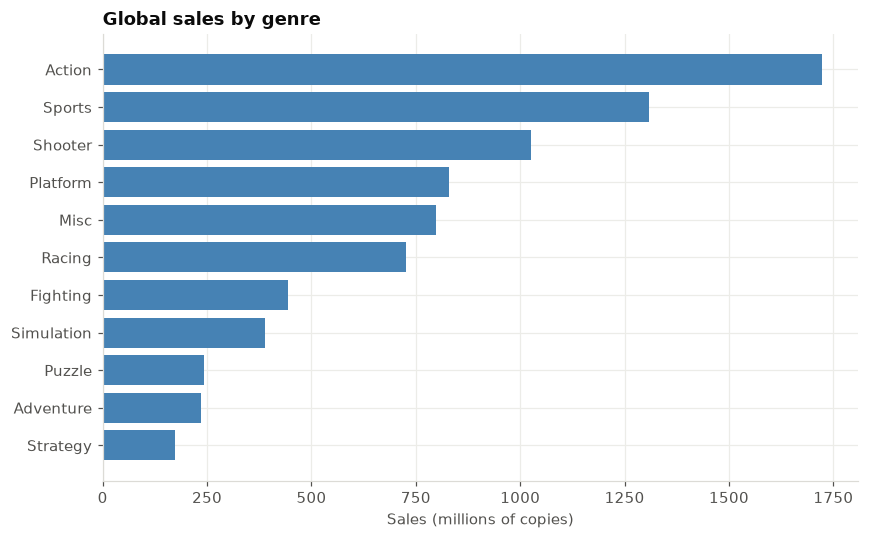

In [135]:
genre_sales = df.groupby("Genre")["Global_Sales"].sum().sort_values()

plt.figure(figsize=(8, 5))
plt.barh(genre_sales.index, genre_sales.values, color="steelblue")
plt.title("Global sales by genre")
plt.xlabel("Sales (millions of copies)")
plt.tight_layout()
plt.show()

### Chart 4: Top 10 platforms

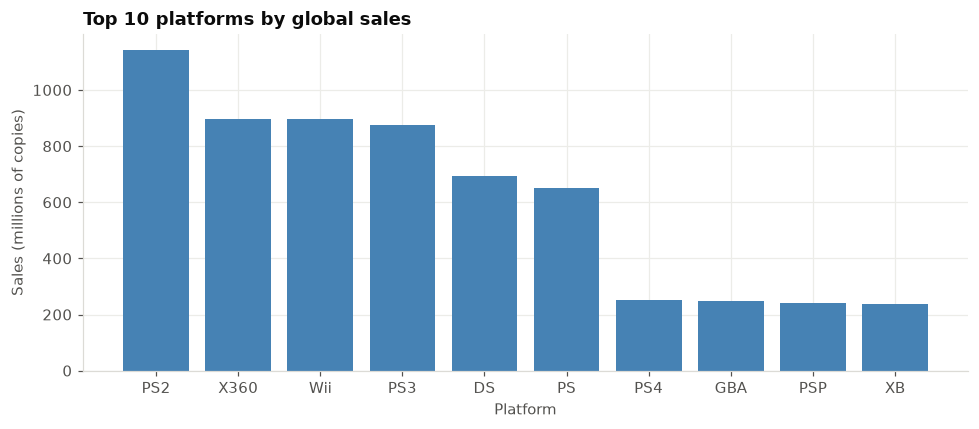

In [136]:
platform_sales = df.groupby("Platform")["Global_Sales"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 4))
plt.bar(platform_sales.index, platform_sales.values, color="steelblue")
plt.title("Top 10 platforms by global sales")
plt.xlabel("Platform")
plt.ylabel("Sales (millions of copies)")
plt.tight_layout()
plt.show()

### Chart 5: Top 10 publishers

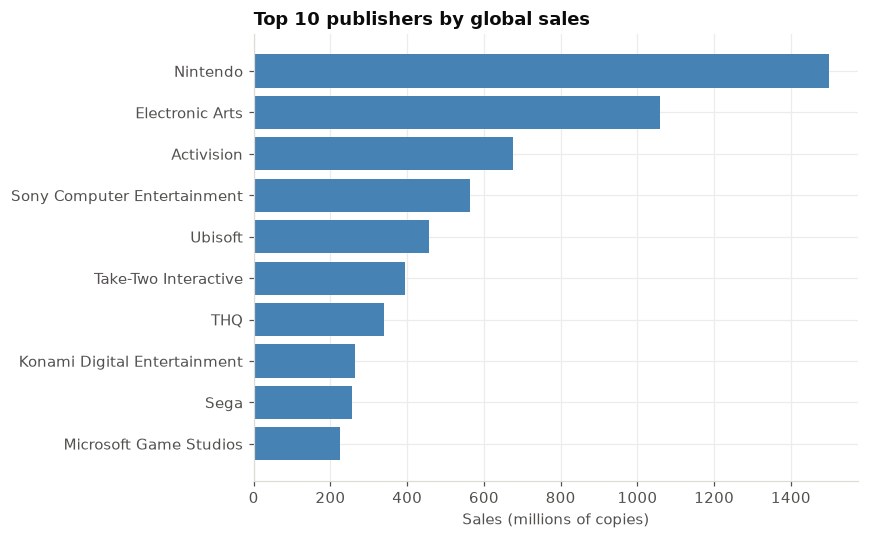

In [ ]:
# leaving out "Unknown" because it is not a real publisher
known = df[df["Publisher"] != "Unknown"]
publisher_sales = known.groupby("Publisher")["Global_Sales"].sum().sort_values().tail(10)

plt.figure(figsize=(8, 5))
plt.barh(publisher_sales.index, publisher_sales.values, color="steelblue")
plt.title("Top 10 publishers by global sales")
plt.xlabel("Sales (millions of copies)")
plt.tight_layout()
plt.show()

### Chart 6: Sales by region

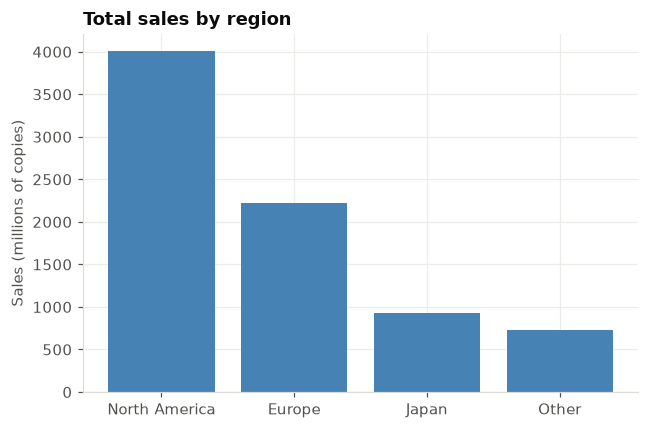

In [138]:
region_sales = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum()

plt.figure(figsize=(6, 4))
plt.bar(["North America", "Europe", "Japan", "Other"], region_sales.values, color="steelblue")
plt.title("Total sales by region")
plt.ylabel("Sales (millions of copies)")
plt.tight_layout()
plt.show()

### Chart 7: Pie chart: which genres make up the sales?

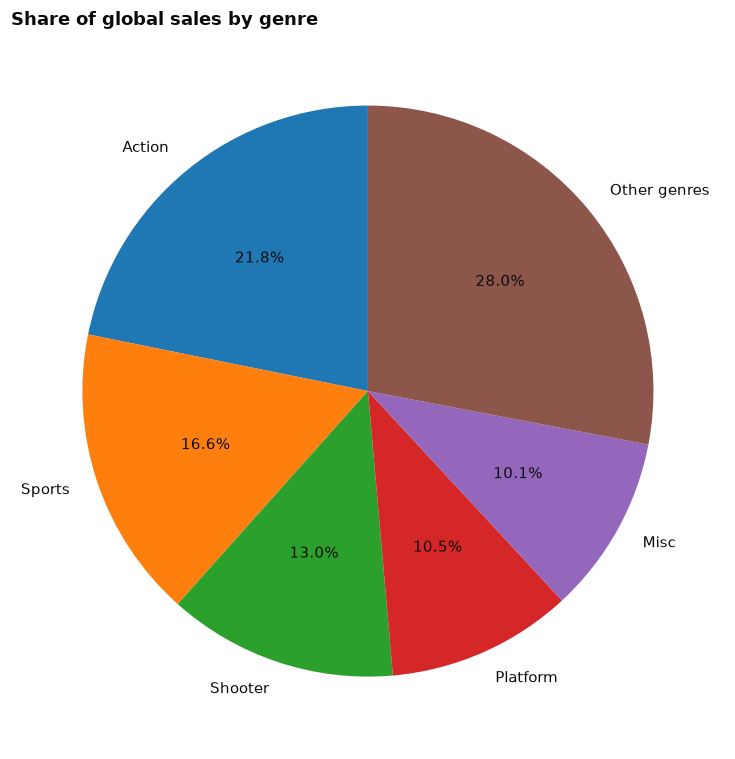

In [139]:
# the 5 biggest genres, and everything else together as "Other genres"
genre_total = df.groupby("Genre")["Global_Sales"].sum().sort_values(ascending=False)
top5 = genre_total.head(5)
other = genre_total.iloc[5:].sum()

pie_values = list(top5.values) + [other]
pie_labels = list(top5.index) + ["Other genres"]

plt.figure(figsize=(7, 7))
plt.pie(pie_values, labels=pie_labels, autopct="%1.1f%%", startangle=90)
plt.title("Share of global sales by genre")
plt.tight_layout()
plt.show()

### Chart 9: Do all regions like the same genres?

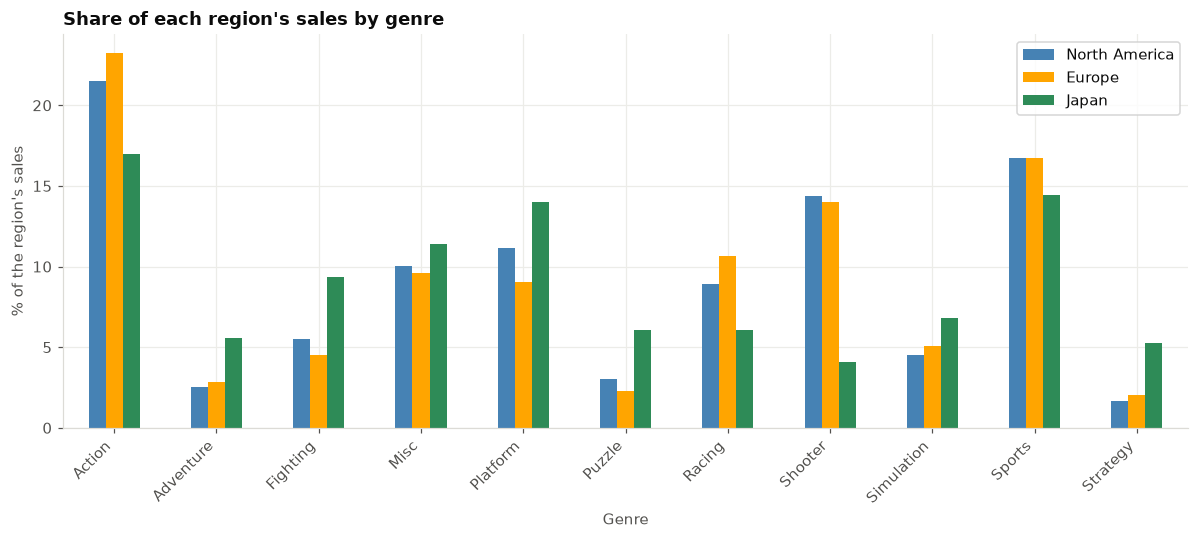

In [140]:
# sales per genre in each region, as a percentage of that region's total
regions = ["NA_Sales", "EU_Sales", "JP_Sales"]
genre_region = df.groupby("Genre")[regions].sum()
genre_percent = genre_region / genre_region.sum() * 100

genre_percent.plot(kind="bar", figsize=(11, 5), color=["steelblue", "orange", "seagreen"])
plt.title("Share of each region's sales by genre")
plt.xlabel("Genre")
plt.ylabel("% of the region's sales")
plt.legend(["North America", "Europe", "Japan"])
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

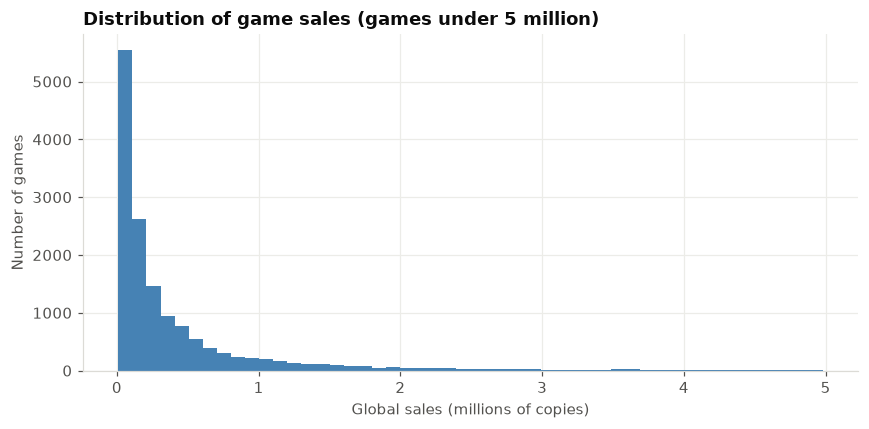

In [141]:
# only games under 5 million so the chart is readable
small = df[df["Global_Sales"] < 5]

plt.figure(figsize=(8, 4))
plt.hist(small["Global_Sales"], bins=50, color="steelblue")
plt.title("Distribution of game sales (games under 5 million)")
plt.xlabel("Global sales (millions of copies)")
plt.ylabel("Number of games")
plt.tight_layout()
plt.show()

### Chart 10: Top 10 best selling games

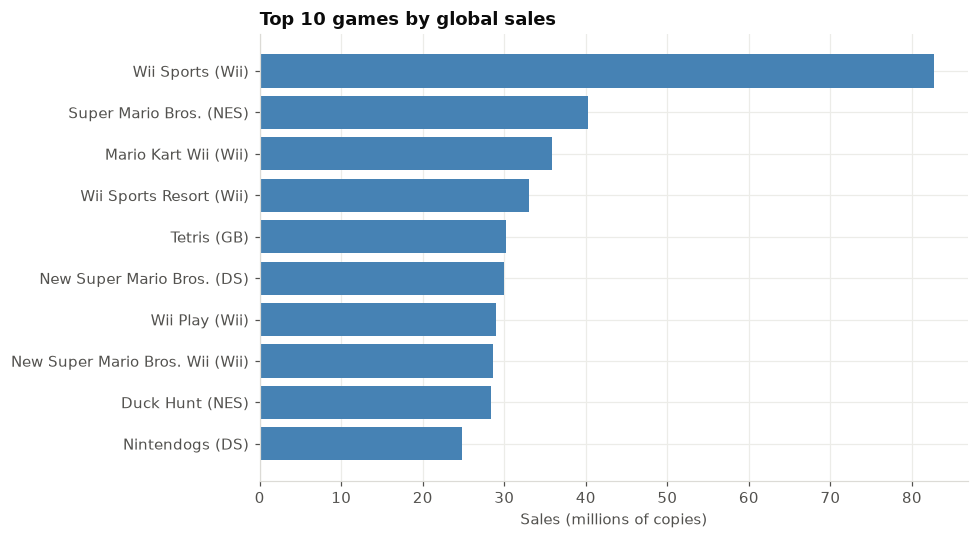

In [144]:
top10 = df.head(10)
labels = top10["Name"] + " (" + top10["Platform"] + ")"

plt.figure(figsize=(9, 5))
plt.barh(labels, top10["Global_Sales"], color="steelblue")
plt.gca().invert_yaxis()
plt.title("Top 10 games by global sales")
plt.xlabel("Sales (millions of copies)")
plt.tight_layout()
plt.show()

## Summary
- The data was already fairly clean: the main problems were missing years and publishers, a few wrong years, one duplicate and two publisher spellings.
- Sales grew until about 2008 and then dropped.
- Action, Sports and Shooter are the biggest genres.
- Games that sell well in North America usually sell well in Europe too.
